## This notebook starts to analyze the model we built using tensorflow. We analyze the results using lineplots, barplots, and finish with violin plots.

In [1]:
#standard libraries
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme("talk")
import matplotlib.pyplot as plt

#sklearn for data manipulation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, normalize


import os
from datetime import datetime

#tensorflow for model building
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, TensorBoard, EarlyStopping
from tensorflow.keras.regularizers import l2

In [2]:
#load in data from directory
progenitor = pd.read_csv("progenitor.csv") #features
antesonic_time = pd.read_csv("antesonic_time.csv")   #make plot with this

In [3]:
#set up our 7 features X
progenitor.drop(["presn_mass","xi_1.75","xi_2.0","xi_2.75","xi_3.0", "Unnamed: 0"], axis = 1, inplace = True)
X = np.asarray(progenitor) #needs to be an array for tensorflow later on

In [4]:
#the features we are using
progenitor.head(5)

,zams,coremass_He,coremass_CO,coremass_Fe,xi_1.5,xi_2.25,xi_2.5
0,9.00,1.571818,1.402958,1.268346,0.005260,0.000041,0.000038
1,9.25,1.784207,1.453464,1.278493,0.028305,0.000054,0.000047
2,9.50,2.042073,1.503286,1.286028,0.093465,0.000091,0.000062
3,9.75,2.306592,1.558010,1.298881,0.305019,0.002272,0.000104
4,10.00,2.477523,1.610957,1.332185,0.455167,0.003974,0.000216


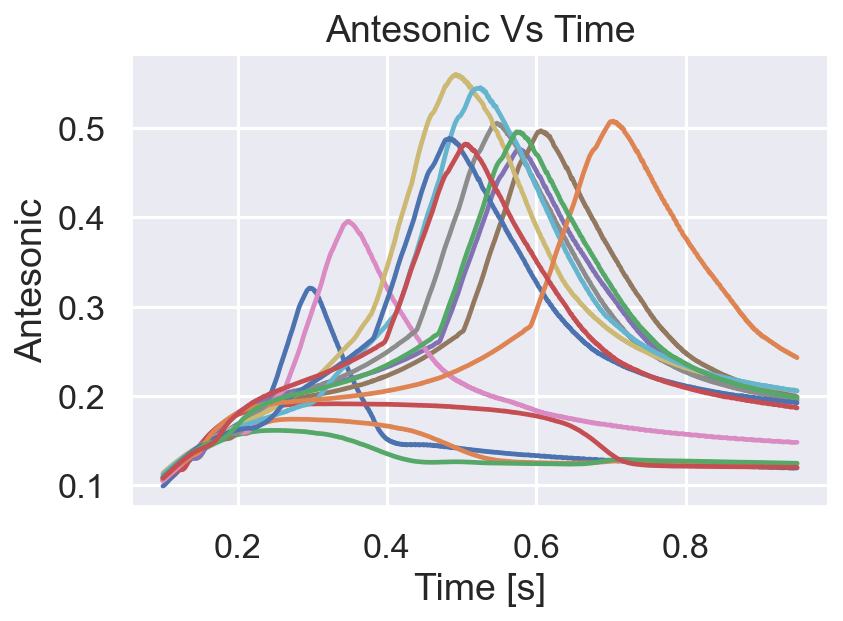

In [5]:
#get a sense of our data
col_names = antesonic_time.columns

plt.figure(dpi = 150)

for i,j in enumerate(col_names[1:]):
    if (i % 15 == 0):
        plt.plot(antesonic_time["time"],antesonic_time[j])
        plt.xlabel("Time [s]")
        plt.ylabel("Antesonic")
        plt.title("Antesonic Vs Time")

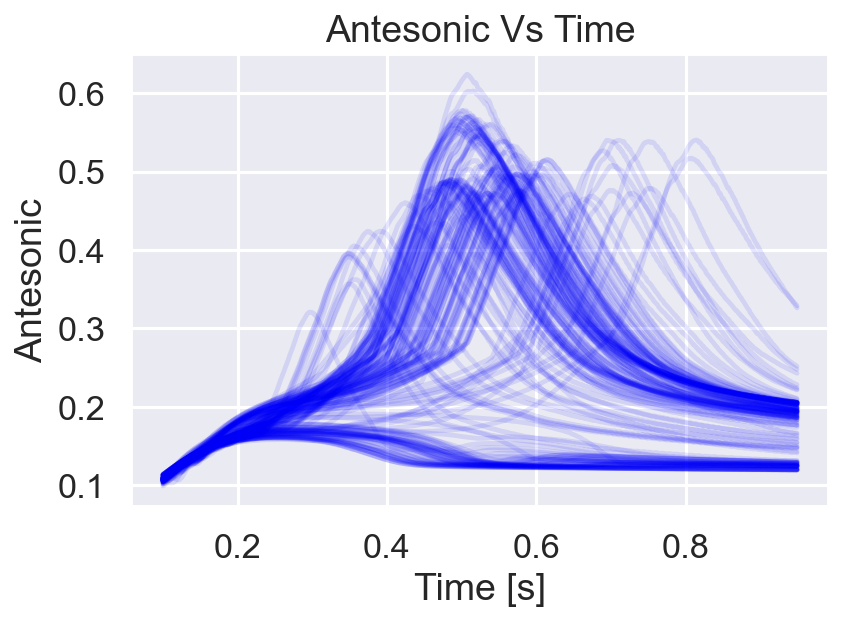

In [6]:
plt.figure(dpi = 150)

max_turb = np.zeros(200)
for i,j in enumerate(col_names[1:]):
        max_turb[i] += np.max(antesonic_time[j])
        plt.plot(antesonic_time["time"],antesonic_time[j], color = "blue", alpha = .1)
        plt.title("Antesonic Vs Time")
        plt.xlabel("Time [s]")
        plt.ylabel("Antesonic")

[]

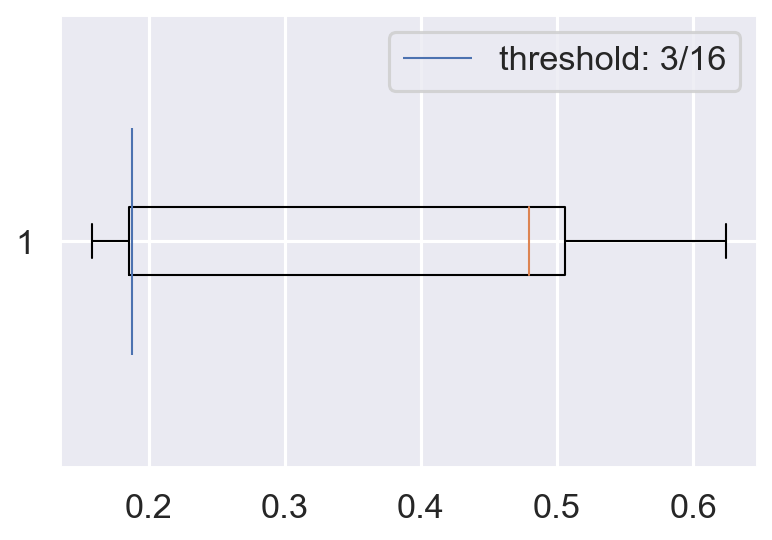

In [7]:
plt.figure(dpi = 150)
plt.boxplot(max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

In [8]:
#extract Y for model building later on
time_feature = antesonic_time.pop("time")
Y = np.asarray(antesonic_time).T

Text(0.5, 1.0, 'Antesonic Vs Time')

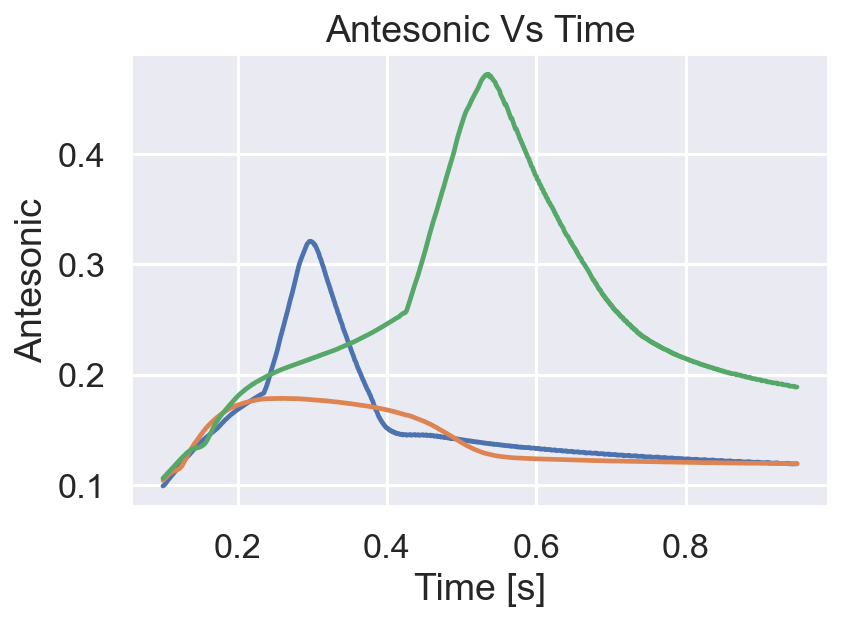

In [9]:
#visualize Y
%matplotlib inline

plt.figure(dpi=150)

plt.plot(time_feature, Y[0])
plt.plot(time_feature, Y[80])
plt.plot(time_feature, Y[50])
plt.xlabel("Time [s]")
plt.ylabel("Antesonic")
plt.title("Antesonic Vs Time")

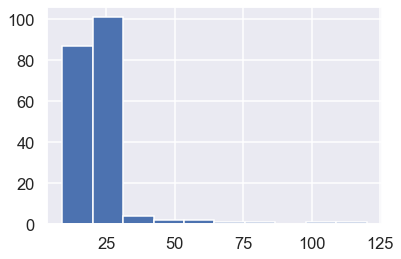

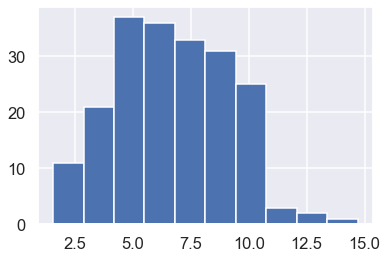

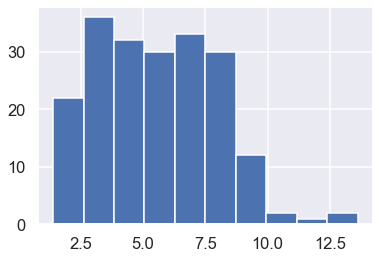

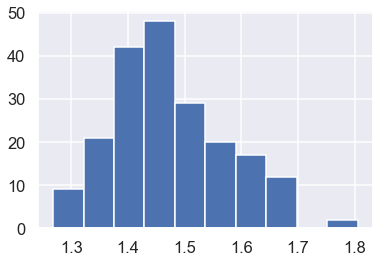

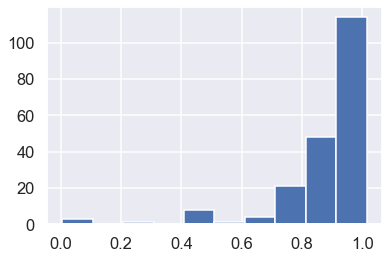

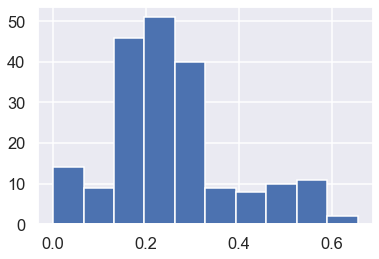

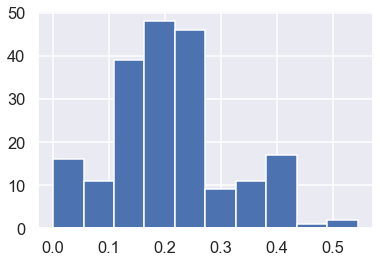

In [10]:

for i in range(7):
    plt.figure()
    plt.hist(X[:,i])

In [11]:
# Preprocess the data (normalize)

X_nn = X.copy()
X_nn[:, 1:] = X_nn[:, 1:]
X_nn[:,0] = np.log(X_nn[:,0])
X_nn[:,4] = np.exp(X_nn[:,4])

X_mean = X_nn.mean(axis=0)
X_std = X_nn.std(axis=0)

X_nn = (X_nn - X_mean) / (X_std)

Y_nn = Y.copy()
Y_nn = np.log(Y_nn + 1e-5)

Y_mean = Y_nn.mean(axis=0)
Y_std = Y_nn.std(axis=0)

Y_nn = (Y_nn - Y_mean) / (Y_std)

(array([ 1.,  3.,  4., 13., 27., 45., 43., 28., 10., 26.]),
 array([-3.2539284 , -2.73810549, -2.22228259, -1.70645969, -1.19063679,
        -0.67481388, -0.15899098,  0.35683192,  0.87265482,  1.38847773,
         1.90430063]),
 <BarContainer object of 10 artists>)

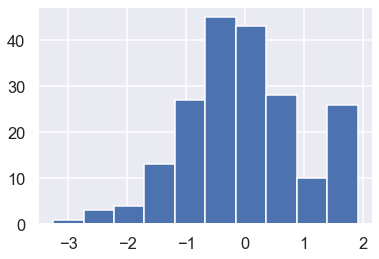

In [12]:
plt.hist(Y_nn[:,0])

In [13]:
# Split the data into training and validation sets

(X_train, 
 X_val,
 Y_train,
 Y_val) = train_test_split(X_nn, Y_nn, train_size=0.7, random_state=42, shuffle=True)

In [14]:
print(X_train.shape)
print(Y_train.shape)
print(X_val.shape)
print(Y_val.shape)

(140, 7)
(140, 850)
(60, 7)
(60, 850)


In [15]:
# Build the model
beta = 0
model = Sequential()
model.add(Dense(256, input_dim=X_nn.shape[1], activation='softplus', kernel_initializer='VarianceScaling', kernel_regularizer = l2(beta), ))
model.add(Dropout(.2))
model.add(Dense(256, activation='softplus', kernel_initializer='VarianceScaling', kernel_regularizer = l2(beta), ))
model.add(Dropout(.2))
model.add(Dense(256, activation='softplus', kernel_initializer='VarianceScaling', kernel_regularizer = l2(beta), ))
model.add(Dropout(.2))
model.add(Dense(Y_nn.shape[1], activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l2(beta)))

model.compile(loss='mean_squared_error', optimizer='adam')
print(model.summary())

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               2048      
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 256)               65792     
                                                                 
 dropout_1 (Dropout)         (None, 256)               0         
                                                                 
 dense_2 (Dense)             (None, 256)               65792     
                                                                 
 dropout_2 (Dropout)         (None, 256)               0         
                                                                 
 dense_3 (Dense)             (None, 850)               2

In [16]:
def train(model, X_train, Y_train, X_val, Y_val, **kwargs):
    
    X_train = tf.convert_to_tensor(X_train)
    Y_train = tf.convert_to_tensor(Y_train)
    Train = (X_train, Y_train)

    X_val = tf.convert_to_tensor(X_val)
    Y_val = tf.convert_to_tensor(Y_val)
    Val = (X_val, Y_val)
    
    cur_date_str = datetime.now().strftime("%Y-%m-%dT%H-%M-%S")
    logdir="logs/scalars/" + cur_date_str
    tensorboard_callback = TensorBoard(log_dir=logdir)
    checkpoints_dir = os.path.join('checkpoints', cur_date_str)
    os.makedirs(checkpoints_dir, exist_ok=True)
    checkpointer_best = ModelCheckpoint(monitor='val_loss', 
                                        filepath=os.path.join(checkpoints_dir, 'grid_weights_best.h5'), 
                                        save_best_only=True, save_weights_only=True)
    early_stopping = EarlyStopping(monitor='val_loss', 
                                   min_delta=0, patience=500, 
                                   verbose=0, mode='auto', baseline=None, 
                                   restore_best_weights=True)
    fit_kwargs = dict(validation_data=Val, 
                  epochs=400000, batch_size=16,
                  callbacks=[checkpointer_best, tensorboard_callback, early_stopping], 
                  verbose=0)
    fit_kwargs.update(kwargs)

    model.fit(*Train, **fit_kwargs)

In [17]:
%%time
train(model, X_train, Y_train, X_val, Y_val, verbose = 1)

Epoch 1/400000
9/9 [==============================] - 1s 22ms/step - loss: 1.3866 - val_loss: 0.9898
Epoch 2/400000
9/9 [==============================] - 0s 8ms/step - loss: 1.0416 - val_loss: 0.9734
Epoch 3/400000
9/9 [==============================] - 0s 8ms/step - loss: 1.0049 - val_loss: 0.9611
Epoch 4/400000
9/9 [==============================] - 0s 8ms/step - loss: 0.9706 - val_loss: 0.9303
Epoch 5/400000
9/9 [==============================] - 0s 8ms/step - loss: 0.9184 - val_loss: 0.8671
Epoch 6/400000
9/9 [==============================] - 0s 7ms/step - loss: 0.8767 - val_loss: 0.8106
Epoch 7/400000
9/9 [==============================] - 0s 8ms/step - loss: 0.8165 - val_loss: 0.7894
Epoch 8/400000
9/9 [==============================] - 0s 8ms/step - loss: 0.7899 - val_loss: 0.7586
Epoch 9/400000
9/9 [==============================] - 0s 7ms/step - loss: 0.7761 - val_loss: 0.7472
Epoch 10/400000
9/9 [==============================] - 0s 8ms/step - loss: 0.7376 - val_loss: 0.745

9/9 [==============================] - 0s 6ms/step - loss: 0.4745 - val_loss: 0.6127
Epoch 83/400000
9/9 [==============================] - 0s 7ms/step - loss: 0.4752 - val_loss: 0.6102
Epoch 84/400000
9/9 [==============================] - 0s 7ms/step - loss: 0.5079 - val_loss: 0.6248
Epoch 85/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.4575 - val_loss: 0.6127
Epoch 86/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.4711 - val_loss: 0.6178
Epoch 87/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.4697 - val_loss: 0.6615
Epoch 88/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.4675 - val_loss: 0.6091
Epoch 89/400000
9/9 [==============================] - 0s 7ms/step - loss: 0.4939 - val_loss: 0.6035
Epoch 90/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.4681 - val_loss: 0.6012
Epoch 91/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.4569 - val_loss: 0.6035
Epoch 

9/9 [==============================] - 0s 6ms/step - loss: 0.3273 - val_loss: 0.5351
Epoch 163/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.3364 - val_loss: 0.5139
Epoch 164/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.3098 - val_loss: 0.5280
Epoch 165/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.3427 - val_loss: 0.4970
Epoch 166/400000
9/9 [==============================] - 0s 7ms/step - loss: 0.3609 - val_loss: 0.4876
Epoch 167/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.3505 - val_loss: 0.5017
Epoch 168/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.3890 - val_loss: 0.5154
Epoch 169/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.3295 - val_loss: 0.5201
Epoch 170/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.3507 - val_loss: 0.5025
Epoch 171/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.3244 - val_loss: 0.49

9/9 [==============================] - 0s 6ms/step - loss: 0.2848 - val_loss: 0.4754
Epoch 243/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2932 - val_loss: 0.4786
Epoch 244/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2532 - val_loss: 0.4815
Epoch 245/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.3249 - val_loss: 0.4883
Epoch 246/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2682 - val_loss: 0.4874
Epoch 247/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2941 - val_loss: 0.4721
Epoch 248/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.3023 - val_loss: 0.4856
Epoch 249/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2648 - val_loss: 0.4530
Epoch 250/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2970 - val_loss: 0.4800
Epoch 251/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2742 - val_loss: 0.49

9/9 [==============================] - 0s 7ms/step - loss: 0.2308 - val_loss: 0.4225
Epoch 323/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2308 - val_loss: 0.4410
Epoch 324/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2109 - val_loss: 0.4300
Epoch 325/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2555 - val_loss: 0.4810
Epoch 326/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2314 - val_loss: 0.4658
Epoch 327/400000
9/9 [==============================] - 0s 7ms/step - loss: 0.2553 - val_loss: 0.4175
Epoch 328/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2673 - val_loss: 0.4777
Epoch 329/400000
9/9 [==============================] - 0s 7ms/step - loss: 0.2628 - val_loss: 0.4548
Epoch 330/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2473 - val_loss: 0.4390
Epoch 331/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.2376 - val_loss: 0.45

...

9/9 [==============================] - 0s 6ms/step - loss: 0.1816 - val_loss: 0.3802
Epoch 1043/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1301 - val_loss: 0.3839
Epoch 1044/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1445 - val_loss: 0.3638
Epoch 1045/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1136 - val_loss: 0.3675
Epoch 1046/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1211 - val_loss: 0.3781
Epoch 1047/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1206 - val_loss: 0.3235
Epoch 1048/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1102 - val_loss: 0.3359
Epoch 1049/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1213 - val_loss: 0.3507
Epoch 1050/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1102 - val_loss: 0.3821
Epoch 1051/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1125 - val_l

9/9 [==============================] - 0s 6ms/step - loss: 0.1095 - val_loss: 0.3772
Epoch 1122/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1056 - val_loss: 0.3916
Epoch 1123/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.0989 - val_loss: 0.4030
Epoch 1124/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1128 - val_loss: 0.3910
Epoch 1125/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1099 - val_loss: 0.3899
Epoch 1126/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1155 - val_loss: 0.3801
Epoch 1127/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1051 - val_loss: 0.3770
Epoch 1128/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1183 - val_loss: 0.3715
Epoch 1129/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1277 - val_loss: 0.3605
Epoch 1130/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1265 - val_l

9/9 [==============================] - 0s 6ms/step - loss: 0.1291 - val_loss: 0.4291
Epoch 1201/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1064 - val_loss: 0.3906
Epoch 1202/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1114 - val_loss: 0.4052
Epoch 1203/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1052 - val_loss: 0.3868
Epoch 1204/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1149 - val_loss: 0.4028
Epoch 1205/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1327 - val_loss: 0.4038
Epoch 1206/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1098 - val_loss: 0.3982
Epoch 1207/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1153 - val_loss: 0.3581
Epoch 1208/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1205 - val_loss: 0.3416
Epoch 1209/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1146 - val_l

9/9 [==============================] - 0s 6ms/step - loss: 0.1143 - val_loss: 0.3585
Epoch 1280/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1050 - val_loss: 0.3476
Epoch 1281/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1313 - val_loss: 0.3623
Epoch 1282/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1338 - val_loss: 0.3479
Epoch 1283/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.0940 - val_loss: 0.3421
Epoch 1284/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.0941 - val_loss: 0.3571
Epoch 1285/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1135 - val_loss: 0.3474
Epoch 1286/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1063 - val_loss: 0.3193
Epoch 1287/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.0845 - val_loss: 0.3171
Epoch 1288/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1160 - val_l

9/9 [==============================] - 0s 8ms/step - loss: 0.0859 - val_loss: 0.3896
Epoch 1359/400000
9/9 [==============================] - 0s 7ms/step - loss: 0.0918 - val_loss: 0.3879
Epoch 1360/400000
9/9 [==============================] - 0s 7ms/step - loss: 0.0905 - val_loss: 0.4026
Epoch 1361/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.0887 - val_loss: 0.4116
Epoch 1362/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1040 - val_loss: 0.4624
Epoch 1363/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1035 - val_loss: 0.4988
Epoch 1364/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.0975 - val_loss: 0.4664
Epoch 1365/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1120 - val_loss: 0.4540
Epoch 1366/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.1375 - val_loss: 0.3845
Epoch 1367/400000
9/9 [==============================] - 0s 6ms/step - loss: 0.0797 - val_l

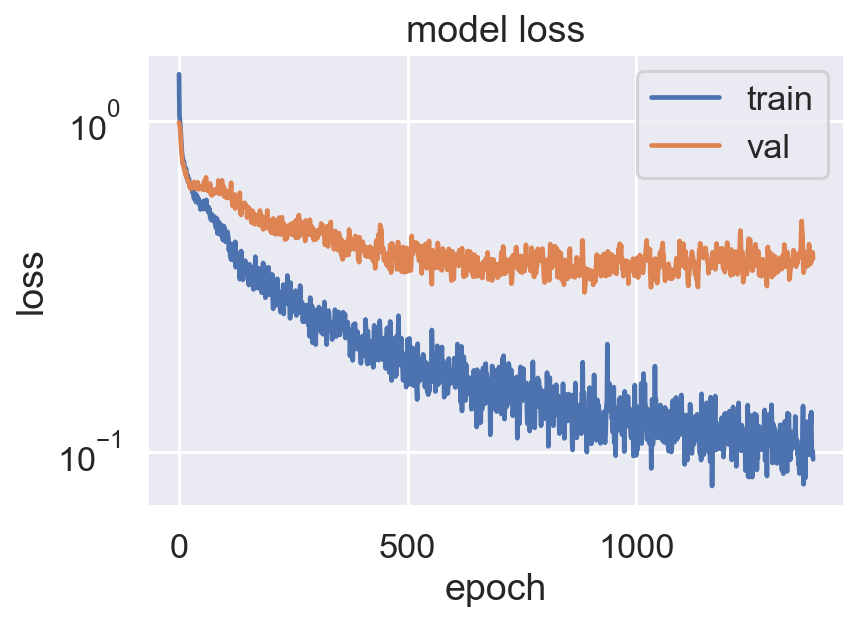

In [18]:
#https://machinelearningmastery.com/display-deep-learning-model-training-history-in-keras/
plt.figure(dpi=150)
plt.plot(model.history.history['loss'])
plt.plot(model.history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'])
plt.yscale("log")
plt.show()

In [19]:
#get the neural networks prediction
Y_nn_test = model(X_val, training = False)
Y_emu_test = np.exp(Y_std * Y_nn_test + Y_mean) - 1e-5

Text(0, 0.5, 'y_true - y_predict')

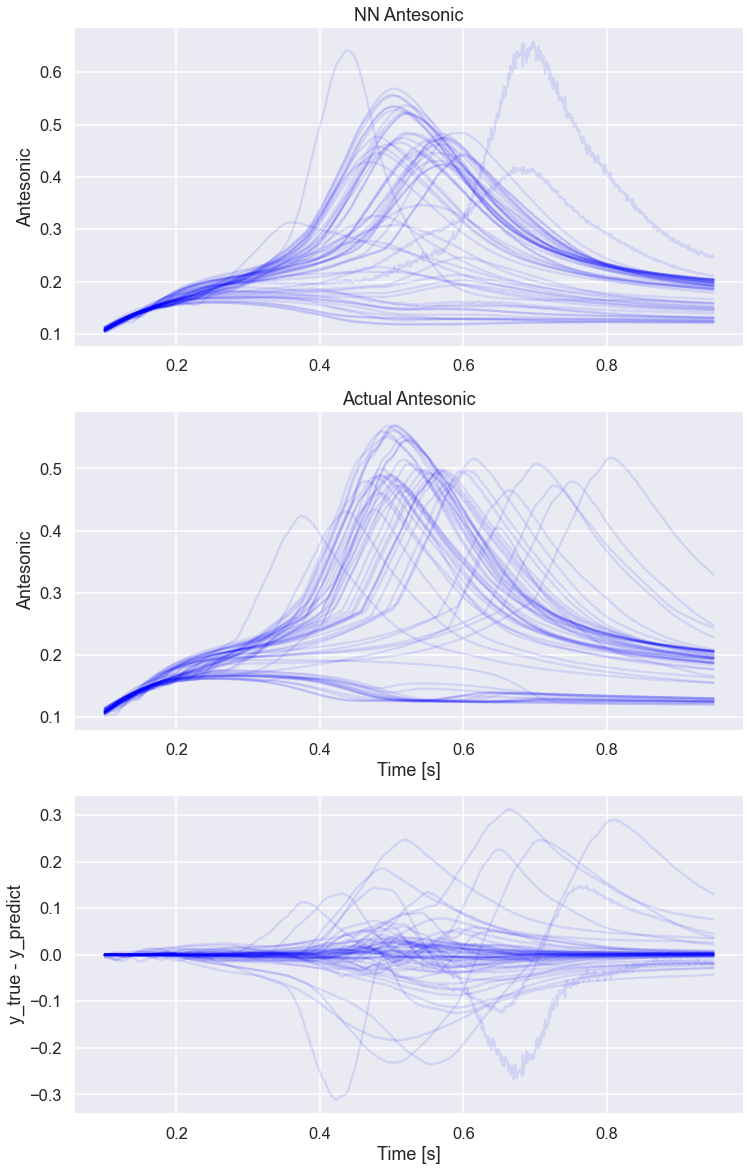

In [20]:
#plot the results
%matplotlib inline

plt.figure(figsize = (12,20))


plt.subplot(3,1,1)
for i in range(len(Y_emu_test)):
    plt.plot(time_feature, Y_emu_test[i], c = "blue", alpha = .1)
    
plt.ylabel("Antesonic")
plt.title("NN Antesonic")


plt.subplot(3,1,2)
y_true = np.exp(Y_std * Y_val + Y_mean) - 1e-5
for i in range(len(y_true)):
    plt.plot(time_feature,y_true[i], color = "blue", alpha = .1)
    
plt.xlabel("Time [s]")
plt.ylabel("Antesonic")
plt.title("Actual Antesonic")

plt.subplot(3,1,3)

for y_t, y_p in zip(y_true, Y_emu_test):
    plt.plot(time_feature, y_t - y_p, color = "blue", alpha = .1)
    
plt.xlabel("Time [s]")
plt.ylabel("y_true - y_predict")

In [21]:
NN_max_turb = np.max(Y_emu_test, axis = 1)

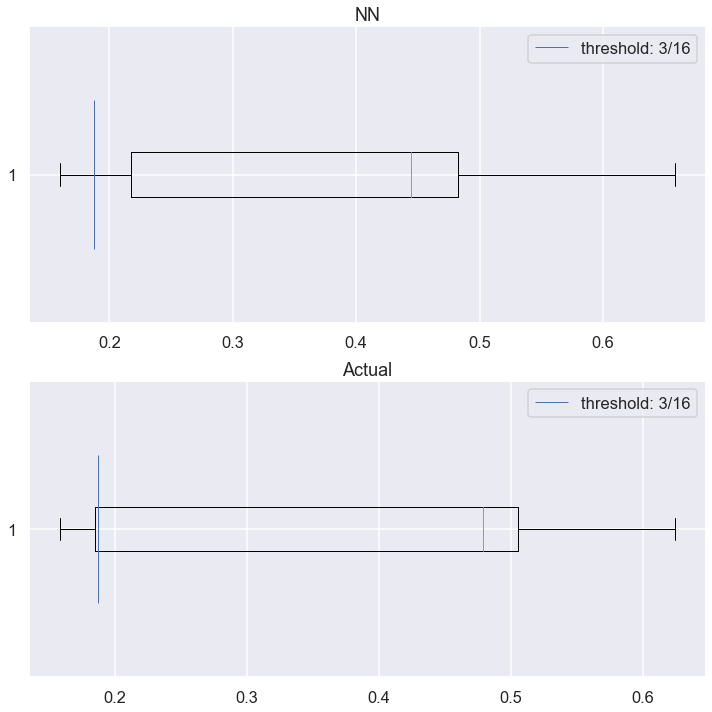

In [22]:
plt.figure(figsize = (10,10))

plt.subplot(2,1,1)
plt.title("NN")
plt.boxplot(NN_max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.subplot(2,1,2)
plt.title("Actual")
plt.boxplot(max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.tight_layout()

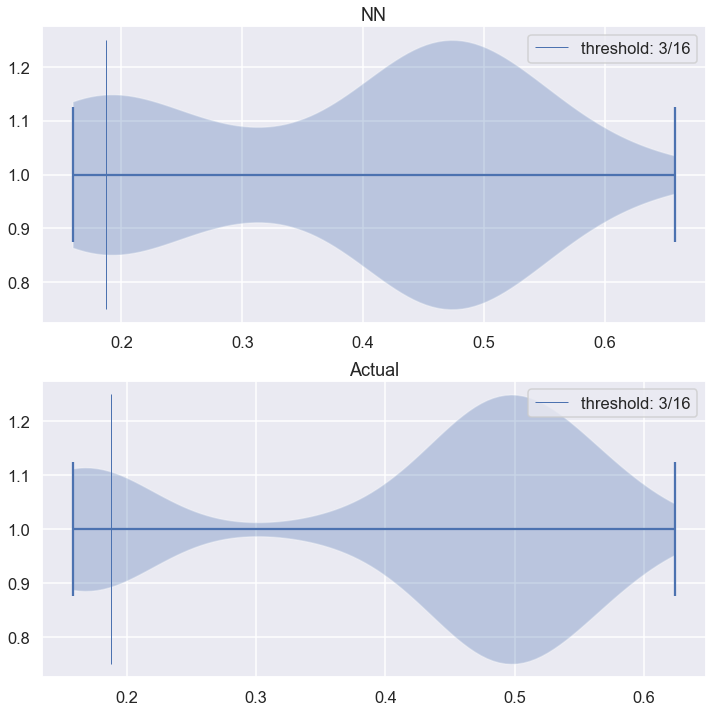

In [23]:
plt.figure(figsize = (10,10))

plt.subplot(2,1,1)
plt.title("NN")
plt.violinplot(NN_max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.subplot(2,1,2)
plt.title("Actual")
plt.violinplot(max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.tight_layout()